### Import Required Libraries

In [2]:
import time, logging
import os, glob, pickle

import pandas as pd
import seaborn as sns
import numpy as np
import seaborn as sns
import scanpy as sc
import networkx as nx
import gseapy as gp
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse
from matplotlib.colors import LinearSegmentedColormap
from arboreto.utils import load_tf_names
from arboreto.algo import grnboost2

from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from pyscenic.utils import modules_from_adjacencies
from pyscenic.prune import prune2df
from pyscenic.transform import df2regulons
from pyscenic.aucell import aucell

### Setting Timestamp

In [3]:
timestamp = time.strftime('%Y%m%d')

### Global Variables

In [4]:
REGION = "T"            
CELL_TYPE = "Activated T cells"
SEED = 42

### Design Definitions

In [5]:
MAIN_COLOR = "#0E2841"
ACCENT_COLOR = "#4E95D9"

NAVY_WHITE = LinearSegmentedColormap.from_list(
    "navy_white",
    ["#0E2841", "#FFFFFF"]
)

COLOR_PALETTE = sns.color_palette(
    [NAVY_WHITE(x) for x in np.linspace(0,1,10)],
    as_cmap=True
)

COLOR_PALETTE_2 = [
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#009E73",  # Bluish green
    "#CC79A7",  # Reddish purple
    "#56B4E9",  # Sky blue
    "#D55E00",  # Vermilion
    "#4D4D4D",  # Dark grey
    "#332288",  # Indigo
    "#88CCEE",  # Light cyan
    "#44AA99",  # Teal
    "#117733",  # Dark green
    "#999933",  # Olive
    "#DDCC77",  # Sand
    "#AA4499",  # Purple
    "#882255",  # Wine
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#263746",
        "xtick.color": "#465563",
        "ytick.color": "#465563",
        "grid.color": "#D9E1E8",
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
    }
)

### Helper Functions

In [6]:
def savefig(path):
    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.close()

## Data Directory Setup

In [7]:
DATA_FOLDER="../data"

SC_EXP_FNAME = os.path.join(DATA_FOLDER, "processed_data/adata_clustered_legacy.h5")
HS_TFS_FNAME = os.path.join(DATA_FOLDER, "pySCENIC/hs_hgnc_tfs.txt")

DATABASES_GLOB = os.path.join(DATA_FOLDER, "pySCENIC/hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather")
MOTIF_ANNOTATIONS_FNAME = os.path.join(DATA_FOLDER, "pySCENIC/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl")

In [8]:
RESULTS_FOLDER="../results"

CELL_TYPE_FOLDER = Path("../results/grn-inference") / CELL_TYPE 
CELL_TYPE_FOLDER.mkdir(parents=True, exist_ok=True)

RESOURCE_FOLDER = Path(os.path.join(CELL_TYPE_FOLDER, REGION))
RESOURCE_FOLDER.mkdir(parents=True, exist_ok=True)

SUBNETWORK_FOLDER = Path(os.path.join(RESOURCE_FOLDER, "subnetwork"))
SUBNETWORK_FOLDER.mkdir(parents=True, exist_ok=True)

In [9]:
MODULES_FNAME = os.path.join(RESOURCE_FOLDER, "pyscenic_modules.p")
MOTIFS_FNAME = os.path.join(RESOURCE_FOLDER, "pyscenic_motifs.p")
REGULONS_FNAME = os.path.join(RESOURCE_FOLDER, "pyscenic_regulons.p")
AUCELL_FNAME = os.path.join(RESOURCE_FOLDER, "pyscenic_aucell.csv")

# Starting Workflow
---

## 1. Loading Preprocessed Adata Object 

In [10]:
adata = sc.read_h5ad(SC_EXP_FNAME)
print(adata)

print(
    f"Initial dimensions: {adata.n_obs:,} cells x "
    f"{adata.n_vars:,} genes"
)

AnnData object with n_obs × n_vars = 13213 × 27792
    obs: 'sample', 'patient', 'region', 'age', 'sex', 'tumor_size', 'lymph_nodes', 'cancer_type', 'grade', 'ER', 'PR', 'HER2', 'Ki67', 'stage', 'treatment', 'tumor_volume', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'size_factors', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.60', 'leiden_res_0.70', 'leiden_res_0.80', 'leiden_res_0.90', 'leiden_res_1.00', 'leiden_res_1.10', 'leiden_res_1.20', 'leiden_r0.20_s0', 'leiden_r0.20_s1', 'leiden_r0.20_s2', 'leiden_r0.20_s3', 'leiden_r0.20_s4', 'leiden_r0.20_s10', 'leiden_r0.20_s21', 'leiden_r0.20_s42', 'leiden_r0.20_s123', 'leiden_r0.20_s2026',

## 2. Extracting Subsets

In [11]:
adata_region = adata[
    (adata.obs["region"] == REGION)
    & (adata.obs["cell_type"] == CELL_TYPE)
].copy()

print(
    f"{REGION} Region - {adata_region.n_obs} cells x "
    f"{adata_region.n_vars} genes"
)

T Region - 412 cells x 27792 genes


### Extracting Raw Counts

In [12]:
X = adata_region.X.toarray()

expression_data = pd.DataFrame(
    X,
    columns=adata_region.var_names,
    index=adata_region.obs_names
)

display(expression_data.head())

gene_symbol,AL627309.1,AL627309.5,AL627309.4,AL669831.2,LINC01409,FAM87B,LINC01128,LINC00115,FAM41C,AL645608.2,...,AL592183.1,AC240274.1,AC004556.3,AC233755.2,AC233755.1,AC136616.1,AC023491.2,AC007325.1,AC007325.4,AC007325.2
barcode,,,,,,,,,,,,,,,,,,,,,
AGCTCAAGTGCTGCAC-T2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CTAGGTAAGTAATTGG-T2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CGTGATAAGTGCAGGT-T2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ATCGTCCAGCTAGATA-T2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CCCTTAGCAGCCTACG-T2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Gene Filtering

In [13]:
print(f"Min: {expression_data.sum(axis=1).min():.2f}")
print(f"Median: {expression_data.sum(axis=1).median():.2f}")
print(f"Max: {expression_data.sum(axis=1).max():.2f}")

Min: 1568.92
Median: 2481.91
Max: 3699.62


In [14]:
min_cells = max(10, int(np.ceil(0.01 * expression_data.shape[0])))
detected = (expression_data > 0).sum(axis=0)
keep_genes = detected >= min_cells

expression_data_filtered = expression_data.loc[:, keep_genes].copy()

n_before = expression_data.shape[1]
n_after = expression_data_filtered.shape[1]

print("Cell type: Tumor - Activated T cells")
print(f"Cells: {expression_data_filtered.shape[0]:,}")
print(f"Genes before filtering: {n_before:,}")
print(f"Genes after filtering: {n_after:,}")
print(f"Genes removed: {n_before - n_after:,} "
      f"({100 * (n_before - n_after) / n_before:.1f}%)")
print(f"Detection threshold: >= {min_cells} cells")
print(f"DataFrame shape: {expression_data_filtered.shape}")

Cell type: Tumor - Activated T cells
Cells: 412
Genes before filtering: 27,792
Genes after filtering: 8,505
Genes removed: 19,287 (69.4%)
Detection threshold: >= 10 cells
DataFrame shape: (412, 8505)


In [15]:
print(f"Min: {expression_data_filtered.sum(axis=1).min():.2f}")
print(f"Median: {expression_data_filtered.sum(axis=1).median():.2f}")
print(f"Max: {expression_data_filtered.sum(axis=1).max():.2f}")

Min: 1526.42
Median: 2412.06
Max: 3586.66


## Derive List of Transcription Factors

In [16]:
tf_names = load_tf_names(HS_TFS_FNAME)
tf_names_present = sorted(set(tf_names).intersection(expression_data_filtered.columns))

print("TFs supplied:", len(tf_names))
print("TFs present:", len(tf_names_present))


TFs supplied: 1839
TFs present: 800


## Input Data Summary 

In [17]:
print("Cells:", expression_data_filtered.shape[0])
print("Genes:", expression_data_filtered.shape[1])
print("TFs:", len(tf_names))

display(expression_data_filtered.head())

Cells: 412
Genes: 8505
TFs: 1839


gene_symbol,LINC01128,NOC2L,PLEKHN1,HES4,ISG15,TNFRSF18,TNFRSF4,SDF4,B3GALT6,UBE2J2,...,MT-CO2,MT-ATP8,MT-ATP6,MT-CO3,MT-ND3,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB
barcode,,,,,,,,,,,,,,,,,,,,,
AGCTCAAGTGCTGCAC-T2,0.0,0.000000,0.000000,0.0,1.486133,0.000000,0.000000,0.000000,0.000000,0.000000,...,4.079900,1.486133,4.333879,3.816825,3.738614,1.486133,4.239879,3.458829,1.486133,4.136118
CTAGGTAAGTAATTGG-T2,0.0,0.000000,1.622036,0.0,1.622036,1.622036,0.000000,0.000000,0.000000,0.000000,...,3.822039,1.622036,4.126341,3.626219,3.382481,1.622036,3.822039,2.848018,0.000000,3.728914
CGTGATAAGTGCAGGT-T2,0.0,0.000000,0.000000,0.0,0.000000,0.000000,1.967650,1.967650,0.000000,0.000000,...,1.967650,0.000000,3.458498,3.458498,2.588342,0.000000,3.243193,2.588342,0.000000,2.588342
ATCGTCCAGCTAGATA-T2,0.0,0.000000,0.000000,0.0,0.000000,2.033412,0.000000,0.000000,0.000000,0.000000,...,3.430124,0.000000,4.348485,3.188020,3.188020,0.000000,3.430124,2.033412,0.000000,3.860324
CCCTTAGCAGCCTACG-T2,0.0,1.343193,0.000000,0.0,1.343193,1.896497,1.343193,1.343193,1.343193,1.343193,...,1.896497,0.000000,3.163366,3.378016,2.511632,1.343193,1.896497,1.343193,0.000000,2.718415


# PHASE I - GRN Inference (GRNBoost2)
---

In [18]:
%%time

network = grnboost2(
    expression_data=expression_data_filtered, 
    tf_names=tf_names_present, 
    seed=SEED,
    verbose=True
)

preparing dask client
parsing input
creating dask graph
5 partitions
computing dask graph
shutting down client and local cluster
finished
CPU times: total: 2min 9s
Wall time: 5min 26s


## Inferred Network Overview

In [19]:
display(network.head())

print("\nColumn Indices: ", network.columns)

print("\nUnique TFs:", network["TF"].nunique())
print("Unique targets:", network["target"].nunique())
print("Unique genes:", len(set(network["TF"]) | set(network["target"])))

print("\nMissing values:\n", network.isna().sum())
print("\nDuplicate edges:", network.duplicated(["TF", "target"]).sum())

,TF,target,importance
789,RPS4X,RPL10,7.880723
578,STAT3,ZNF587B,7.622914
625,KDM4B,SMCR8,7.505604
454,KDM2B,RSAD1,7.177813
102,RBMS1,LPAR6,7.071214



Column Indices:  Index(['TF', 'target', 'importance'], dtype='object')

Unique TFs: 800
Unique targets: 8505
Unique genes: 8505

Missing values:
 TF            0
target        0
importance    0
dtype: int64

Duplicate edges: 0


In [44]:
display(pd.DataFrame(network["importance"].describe()))

,importance
count,7.253440e+05
mean,3.111861e-01
std,4.147083e-01
min,1.647314e-17
25%,9.494156e-02
50%,1.902376e-01
75%,3.566495e-01
max,7.880723e+00


## Create Edge Table

In [45]:
edges = network.rename(columns={
    "TF": "source",
    "target": "target",
    "importance": "importance"
}).copy()

edges = edges.dropna()
edges = edges[edges["importance"] >= 0]

# combines repeated TF-Target interactions
edges = (edges.groupby(["source", "target"], as_index=False)["importance"].max())

display(edges)

,source,target,importance
0,ABCF2,AAMDC,0.870455
1,ABCF2,AARS,0.225736
2,ABCF2,ABAT,0.193172
3,ABCF2,ABHD3,0.249574
4,ABCF2,ABRAXAS2,0.438278
...,...,...,...
725339,ZXDC,ZNF510,0.101606
725340,ZXDC,ZNF562,0.718961
725341,ZXDC,ZNF644,0.064026
725342,ZXDC,ZNRD1,0.466164


## Edge Filtering

In [46]:
q95 = edges["importance"].quantile(0.95)
edges_top5pct = edges[edges["importance"] >= q95].copy()

edges_top10_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("source", group_keys=False)
    .head(10).copy())

edges_top25_per_tf = (
    edges
    .sort_values("importance", ascending=False)
    .groupby("source", group_keys=False)
    .head(25).copy()
)

print("Full Network:", len(edges))
print("Top 5% globally:", len(edges_top5pct))
print("Top 10 per TF:", len(edges_top10_per_tf))
print("Top 25 per TF:", len(edges_top25_per_tf))

Full Network: 725344
Top 5% globally: 36268
Top 10 per TF: 8000
Top 25 per TF: 20000


## Adjacency Table 

In [47]:
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr="importance",
    create_using=nx.DiGraph()
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

Nodes: 8505
Edges: 725344
Density: 0.01002874187780637


### Standard Topology Metrics

In [48]:
tf_set = set(tf_names_present)
all_nodes = set(G.nodes())

tf_nodes = all_nodes & tf_set
target_nodes = {
    node for node in G.nodes()
    if G.in_degree(node) > 0
}
tf_target_nodes = tf_nodes & target_nodes
tf_regulators = {
    node for node in tf_nodes
    if G.out_degree(node) > 0
}

In [49]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

weighted_out_degree = dict(
    G.out_degree(weight="importance")
)

weighted_in_degree = dict(
    G.in_degree(weight="importance")
)

pagerank = nx.pagerank(G, weight="importance")

In [50]:
node_metrics = pd.DataFrame({
    "gene": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[n] for n in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[n] for n in G.nodes()
    ],
    "pagerank": [pagerank[n] for n in G.nodes()],
})

node_metrics["is_TF"] = node_metrics["gene"].isin(tf_nodes)
node_metrics["is_target"] = node_metrics["gene"].isin(target_nodes)
node_metrics["is_TF_target"] = node_metrics["gene"].isin(tf_target_nodes)
node_metrics["is_regulator"] = node_metrics["gene"].isin(tf_regulators)

tf_ranking = (
    node_metrics[node_metrics["is_TF"]]
    .sort_values("weighted_out_degree", ascending=False)
)

display(tf_ranking.head(10))

,gene,in_degree,out_degree,weighted_in_degree,weighted_out_degree,pagerank,is_TF,is_target,is_TF_target,is_regulator
7594,RPS4X,96,2726,26.0,1537.562183,0.000116,True,True,True,True
8036,JUND,104,2814,29.0,1142.468405,0.000117,True,True,True,True
3559,JUNB,137,3810,35.0,1049.540313,0.000117,True,True,True,True
5692,FOS,108,2632,30.0,982.948799,0.000115,True,True,True,True
3566,KLF6,115,3164,29.0,944.614669,0.000114,True,True,True,True
570,YWHAZ,103,3948,26.0,909.370407,0.000118,True,True,True,True
7325,BATF,130,2441,37.0,819.622191,0.000117,True,True,True,True
5900,RPL6,110,2598,27.0,794.705346,0.000116,True,True,True,True
5438,RPL35,104,2850,26.0,780.967527,0.000117,True,True,True,True
1173,CREM,120,2519,26.0,764.031674,0.000116,True,True,True,True


In [51]:
node_metrics.to_csv(
    os.path.join(RESOURCE_FOLDER, "grn_node_metrics.csv"),
    sep="\t",
    index=False
)

### Importance Score Distribution

In [52]:
importance = (
    network["importance"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

importance = importance[importance > 0]

print("Original skewness:", importance.skew())
print("Log10-transformed skewness:", np.log10(importance).skew())

Original skewness: 3.4398969585820343
Log10-transformed skewness: -3.7567695034550517


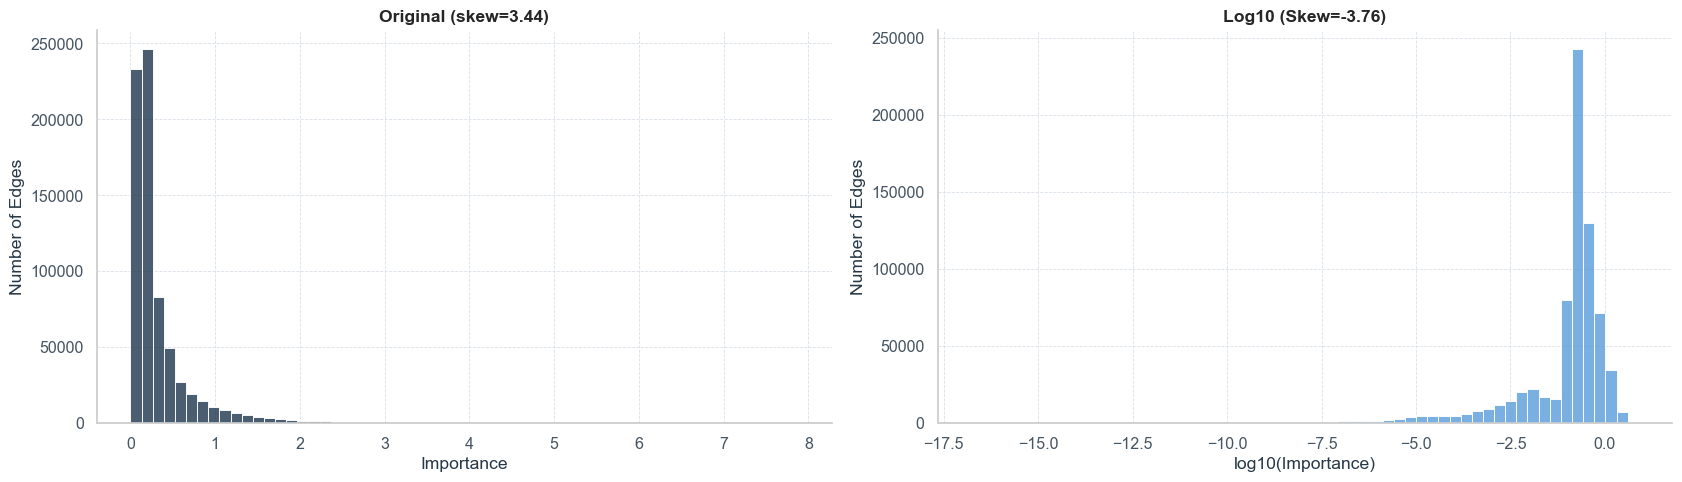

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# original values
sns.histplot(importance, bins=60, ax=axes[0], color=MAIN_COLOR)
axes[0].set_title(f"Original (skew={importance.skew():.2f})")
axes[0].set_xlabel("Importance")

# log10-transformed values
log_importance = np.log10(importance)
sns.histplot(log_importance, bins=60, ax=axes[1], color=ACCENT_COLOR)
axes[1].set_title(f"Log10 (Skew={log_importance.skew():.2f})")
axes[1].set_xlabel("log10(Importance)")

for ax in axes:
    ax.set_ylabel("Number of Edges")

plt.tight_layout()
plt.show()
savefig(os.path.join(RESOURCE_FOLDER, "network_importance_distribution_summary.jpg"))

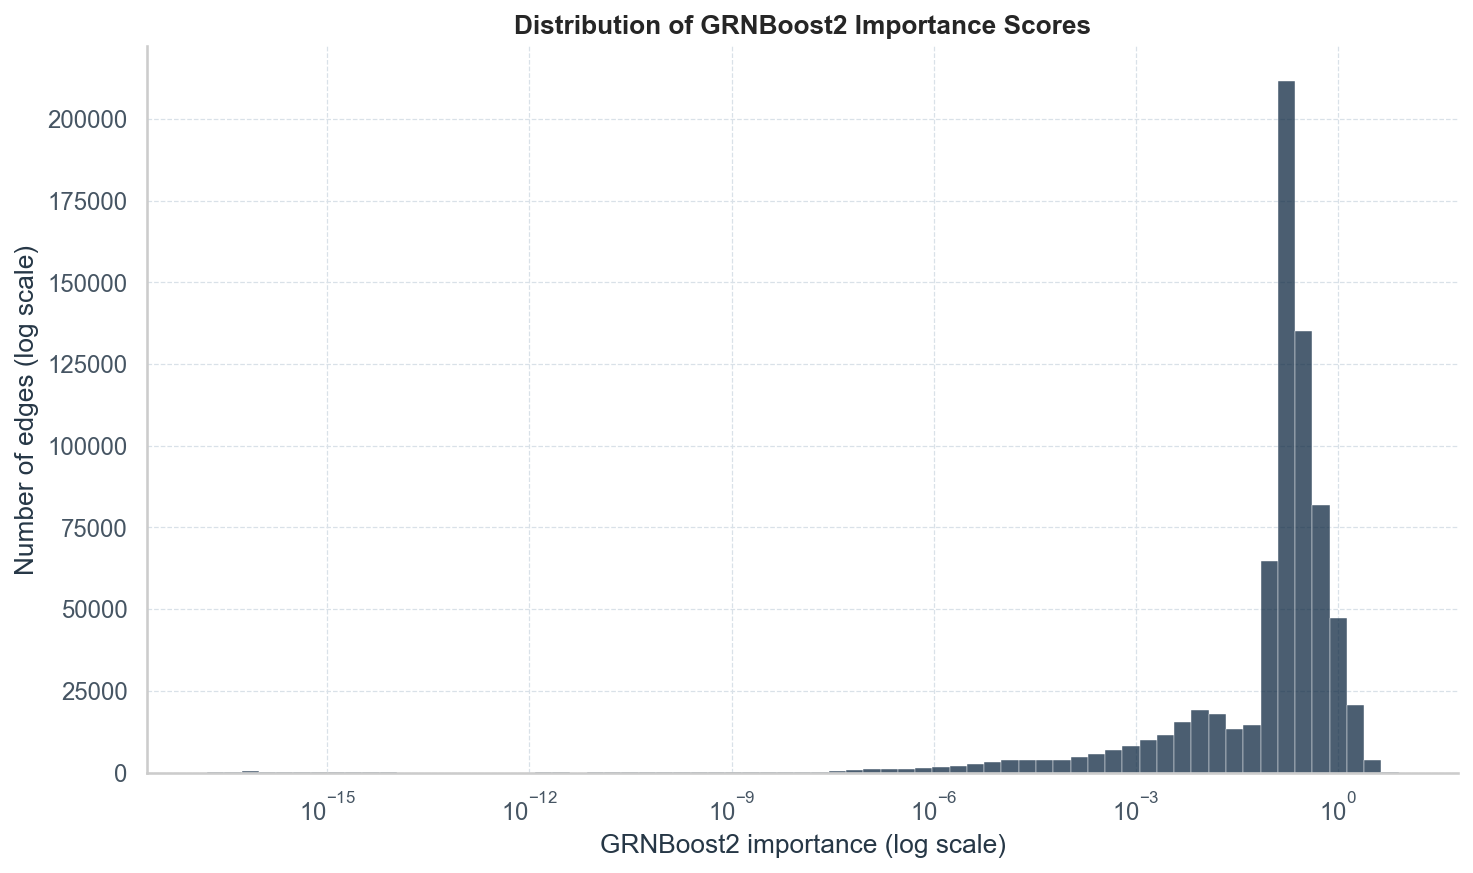

In [58]:
# log-scaled bins
bins = np.logspace(
    np.log10(importance.min()),
    np.log10(importance.max()),
    70
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

sns.histplot(
    importance,
    bins=bins,
    color=MAIN_COLOR,
    linewidth=0.2,
    ax=ax
)

ax.set_xscale("log")
ax.set_xlabel("GRNBoost2 importance (log scale)")
ax.set_ylabel("Number of edges (log scale)")
ax.set_title("Distribution of GRNBoost2 Importance Scores")

plt.tight_layout()
plt.show()
savefig(os.path.join(RESOURCE_FOLDER, "network_importance_distribution_log.jpg"))

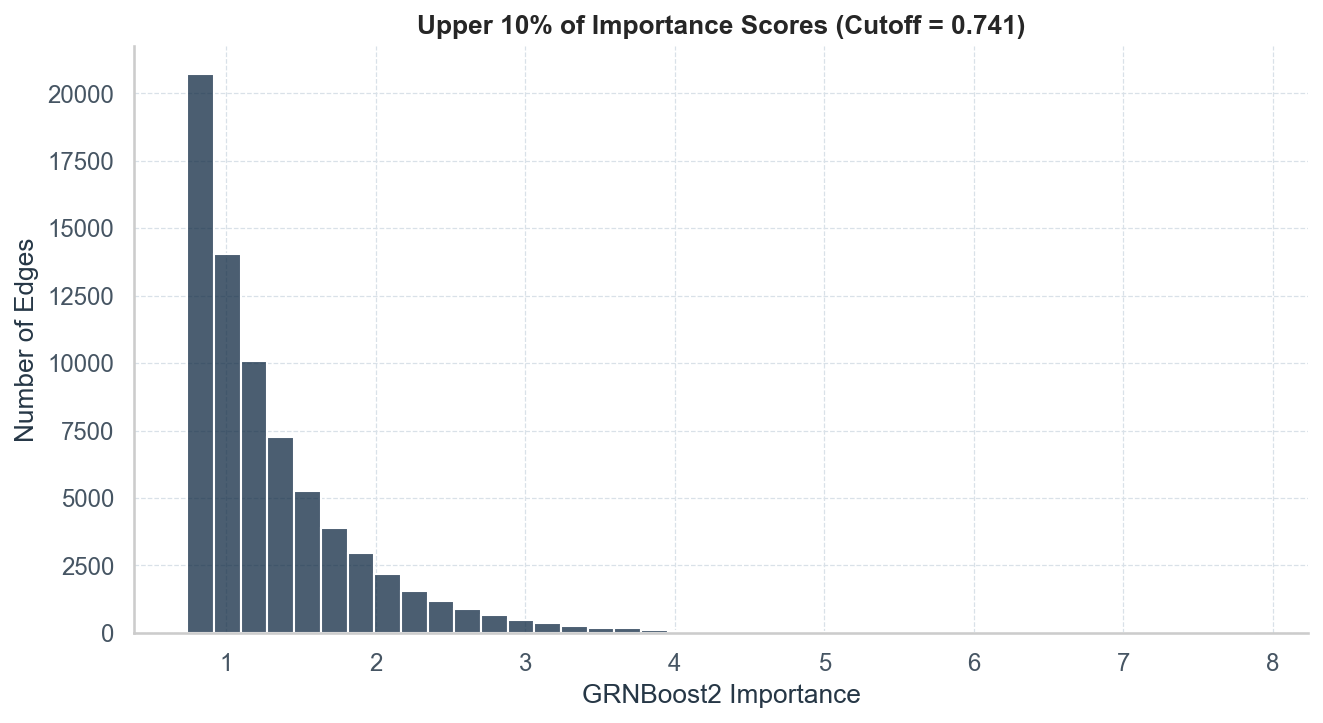

In [38]:
cutoff = importance.quantile(0.90)
upper = importance[importance >= cutoff]

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    upper,
    bins=40,
    color=MAIN_COLOR,
    ax=ax
)

ax.set_xlabel("GRNBoost2 Importance")
ax.set_ylabel("Number of Edges")
ax.set_title(
    f"Upper 10% of Importance Scores (Cutoff = {cutoff:.3f})"
)

plt.tight_layout()
plt.show()
savefig(RESOURCE_FOLDER / "network_importance_distribution_top10.jpg")

### Top-Ranked Edges

In [59]:
top_edges = network.nlargest(
    100, "importance"
).copy()

# Summarize the strongest candidate regulators
top_tf_summary = (
    top_edges.groupby("TF")
    .agg(
        edges_in_top100=("target", "nunique"),
        max_importance=("importance", "max"),
        mean_importance=("importance", "mean")
    )
    .sort_values("max_importance", ascending=False)
)

display(top_tf_summary.head(10))

,edges_in_top100,max_importance,mean_importance
TF,,,
RPS4X,34,7.880723,5.418998
STAT3,2,7.622914,6.215319
KDM4B,1,7.505604,7.505604
KDM2B,1,7.177813,7.177813
RBMS1,5,7.071214,5.517660
SP4,1,6.922924,6.922924
GABPA,1,6.262621,6.262621
ZNF513,1,6.249973,6.249973
JUNB,1,6.202726,6.202726


### Highly Regulated Genes and TF Convergence

In [60]:
top_regulated_genes = (
    node_metrics
    .sort_values("in_degree", ascending=False)
    .head(10)
)

display(top_regulated_genes[["gene", "in_degree", "weighted_in_degree"]])

,gene,in_degree,weighted_in_degree
3750,SNU13,169,39.0
4029,DDX21,167,40.0
767,LBH,165,41.0
2155,ATP6V0E1,163,37.0
2348,GBP5,163,44.0
7393,DHX36,161,36.0
7332,BTG2,159,36.0
5836,PCBP1,159,35.0
4409,SAT1,156,42.0
4347,PSMB8,155,36.0


In [61]:
top_tfs = tf_ranking.head(10)["gene"].tolist()

tf_target_matrix = (
    edges[edges["source"].isin(top_tfs)]
    .pivot_table(
        index="target",
        columns="source",
        values="importance",
        aggfunc="max",
        fill_value=0
    )
)

tf_target_matrix["n_top_TFs"] = (
    tf_target_matrix[top_tfs] > 0
).sum(axis=1)

tf_target_matrix["total_importance"] = (
    tf_target_matrix[top_tfs].sum(axis=1)
)

convergent_targets = tf_target_matrix.sort_values(
    ["n_top_TFs", "total_importance"],
    ascending=[False, False]
)

display(convergent_targets.head(10))

source,BATF,CREM,FOS,JUNB,JUND,KLF6,RPL35,RPL6,RPS4X,YWHAZ,n_top_TFs,total_importance
target,,,,,,,,,,,,
PRDM1,1.569237,0.258241,0.130235,0.092748,0.966212,2.332814,0.471850,1.049297,2.371124,0.151966,10,9.393725
PRPF4B,0.897563,0.104087,0.180165,0.950973,0.000103,0.214721,0.429149,0.441857,2.046379,0.177963,10,5.442960
FOXP3,0.497215,0.160923,0.108110,0.204584,0.424340,0.207615,0.264580,0.067857,1.917644,0.083769,10,3.936636
DDHD1,1.667457,0.114528,0.150329,0.084963,0.141436,0.096227,0.450082,0.100716,0.499022,0.218280,10,3.523041
INO80D,0.000002,0.000932,0.072067,0.005532,0.009293,0.010410,0.101940,0.370793,0.196558,0.203194,10,0.970721
TXNIP,0.229197,0.086870,4.874551,4.544318,0.086166,3.748365,0.094247,0.000000,0.879188,0.204129,9,14.747033
FOSB,0.044354,0.149128,4.560243,1.176540,1.546423,4.178136,0.143993,0.220032,0.692114,0.000000,9,12.710963
RGS1,0.127586,0.819573,0.728137,2.258632,0.157664,3.314072,0.635474,0.000000,1.435672,0.450111,9,9.926923
GK,0.162590,0.510358,3.582266,1.512275,0.299329,1.224207,0.186540,0.525374,0.320392,0.000000,9,8.323331


### Identify Communities and Regulatory Modules

In [62]:
G_filtered = nx.from_pandas_edgelist(
    edges_top10_per_tf,
    source="source",
    target="target",
    edge_attr="importance",
    create_using=nx.DiGraph()
)

In [63]:
U = nx.Graph()
U.add_nodes_from(G_filtered.nodes())

for u, v, data in G_filtered.edges(data=True):
    w = float(data["importance"])

    if U.has_edge(u, v):
        U[u][v]["weight"] += w
    else:
        U.add_edge(u, v, weight=w)

communities = nx.community.louvain_communities(
    U,
    weight="weight",
    seed=SEED
)

In [64]:
module_rows = []

for module_id, genes in enumerate(communities, start=1):
    for gene in genes:
        module_rows.append({
            "gene": gene,
            "module": module_id,
            "is_TF": gene in tf_set
        })

modules_df = pd.DataFrame(module_rows)

module_summary = (
    modules_df.groupby("module")
    .agg(
        n_genes=("gene", "nunique"),
        n_TFs=("is_TF", "sum")
    )
)

module_summary["TF_fraction"] = (
    module_summary["n_TFs"] / module_summary["n_genes"]
)

module_summary = module_summary.sort_values(
    "n_genes", ascending=False
)

display(module_summary.head(10))

,n_genes,n_TFs,TF_fraction
module,,,
55,182,28,0.153846
45,170,27,0.158824
43,162,25,0.154321
52,155,26,0.167742
44,151,19,0.125828
19,150,25,0.166667
50,144,20,0.138889
2,142,21,0.147887
10,140,22,0.157143


In [65]:
modules_df.to_csv(
    os.path.join(RESOURCE_FOLDER, "grn_modules.csv"),
    sep="\t",
    index=False
)

### Functional Enrichment of TF Targets

In [66]:
candidate_tfs = tf_ranking.head(20)["gene"].tolist()

background_genes = list(expression_data_filtered.columns)

enrichment_results = []

for tf in candidate_tfs:
    targets = (
        edges.loc[edges["source"] == tf]
        .sort_values("importance", ascending=False)["target"]
        .drop_duplicates()
        .tolist()
    )

    if len(targets) < 10:
        continue

    result = gp.enrichr(
        gene_list=targets,
        gene_sets=[
            "GO_Biological_Process_2023",
            "KEGG_2021_Human",
            "Reactome_2022"
        ],
        organism="hsapiens",  
        outdir=None
    )

    table = result.results.copy()
    table["TF"] = tf
    table["n_targets"] = len(targets)

    enrichment_results.append(table)

In [68]:
if enrichment_results:
    tf_enrichment = pd.concat(
        enrichment_results, ignore_index=True
    )

    tf_enrichment.to_csv(
        os.path.join(RESOURCE_FOLDER, "tf_functional_enrichment.csv"),
        sep="\t",
        index=False
    )

    display(
        tf_enrichment.sort_values("Adjusted P-value")
        [["TF", "Term", "Adjusted P-value", "Genes"]]
        .head(5)
    )

,TF,Term,Adjusted P-value,Genes
4761,RPS4X,Metabolism Of RNA R-HSA-8953854,1.214902e-63,RPL4;EIF4A2;LTV1;POP5;RPL5;EIF4A1;RPL30;NUP107...
76088,EEF1D,Metabolism Of RNA R-HSA-8953854,4.913451e-61,EIF4A2;RPL5;EIF4A1;RPL30;POP7;RPL3;RPL32;RPL34...
50412,RPL6,SRP-dependent Cotranslational Protein Targetin...,2.802330e-57,RPL4;RPL5;RPL30;RPL3;RPL32;RPL31;RPL34;RPLP1;R...
4762,RPS4X,L13a-mediated Translational Silencing Of Cerul...,3.066956e-57,EIF4A2;RPL4;EIF4A1;RPL5;RPL30;RPL3;RPL32;RPL31...
4763,RPS4X,GTP Hydrolysis And Joining Of 60S Ribosomal Su...,1.019512e-56,EIF4A2;RPL4;EIF4A1;RPL5;RPL30;RPL3;RPL32;RPL31...


## Table Creation for Cytoscape Import

In [69]:
viz_edges = (
    edges_top10_per_tf
    .drop_duplicates(subset=["source", "target"])
    .reset_index(drop=True)
)

viz_edges.to_csv(
    RESOURCE_FOLDER / "cytoscape_edges.csv",
    index=False
)

viz_nodes = node_metrics.copy()

gene_modules = (
    modules_df[["gene", "module"]]
    .drop_duplicates(subset=["gene"])
)

viz_nodes = (
    viz_nodes
    .drop(columns=["module"], errors="ignore")
    .merge(
        gene_modules,
        on="gene",
        how="left",
        validate="one_to_one"
    )
)

source_genes = set(edges["source"].dropna())
target_genes = set(edges["target"].dropna())

viz_nodes["is_TF"] = viz_nodes["gene"].isin(tf_set)
viz_nodes["is_regulator"] = viz_nodes["gene"].isin(source_genes)
viz_nodes["is_target"] = viz_nodes["gene"].isin(target_genes)
viz_nodes["is_TF_target"] = (
    viz_nodes["is_TF"] & viz_nodes["is_target"]
)

viz_nodes["node_type"] = np.select(
    [
        viz_nodes["is_TF"] & viz_nodes["is_target"],
        viz_nodes["is_TF"],
        viz_nodes["is_target"],
    ],
    [
        "TF_Target",
        "TF",
        "Target",
    ],
    default="Other"
)

viz_nodes["module"] = (
    viz_nodes["module"].astype("Int64")
)

viz_nodes["weighted_out_rank"] = (
    viz_nodes["weighted_out_degree"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

viz_nodes = viz_nodes.sort_values(
    ["node_type", "gene"]
).reset_index(drop=True)

viz_nodes.to_csv(
    RESOURCE_FOLDER / "cytoscape_nodes.csv",
    index=False
)

print(f"Exported {len(viz_edges)} edges")
print(f"Exported {len(viz_nodes)} nodes")

print("\nNode types:")
display(
    pd.DataFrame(
        viz_nodes["node_type"].value_counts(dropna=False)
    )
)

print("\nNodes by module:")
display(
    pd.DataFrame(
        viz_nodes["module"]
        .value_counts(dropna=False)
        .sort_index()
        .head()
    )
)

Exported 8000 edges
Exported 8505 nodes

Node types:


,count
node_type,
Target,7705
TF_Target,800



Nodes by module:


,count
module,
1,66
2,142
3,96
4,116
5,74


# PHASE 2 - Prune Modules for Targets (RcisTarget)
--- 

In [ ]:
db_fnames = glob.glob(DATABASES_GLOB)
    
dbs = [RankingDatabase(
    fname=fname, name=os.path.splitext(os.path.basename(fname))[0]
    ) for fname in db_fnames
]

print(dbs)

[FeatherRankingDatabase(name="hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings")]


In [ ]:
modules = list(modules_from_adjacencies(network, expression_data_filtered))

with open(MODULES_FNAME, 'wb') as f:
    pickle.dump(modules, f)


2026-10-14 00:51:01,972 - pyscenic.utils - INFO - Calculating Pearson correlations.

2026-10-14 00:51:02,266 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2026-10-14 00:51:29,057 - pyscenic.utils - INFO - Creating modules.
c:\Users\oonak\anaconda3\envs\pyscenic\lib\site-packages\pyscenic\utils.py:244: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of panda

In [ ]:
print("Total modules:", len(modules))
print("Module type:", type(modules[0]) if modules else None)

if modules:
    print("\nFirst module:")
    print(modules[0])

Total modules: 4703
Module type: <class 'ctxcore.genesig.Regulon'>

First module:
[EMC6,LAS1L,ESF1,PAFAH1B3,TMEM208,AC004889.1,OFD1,KPNA2,TUBGCP4,RND1,ZDHHC24,EIF2B2,RNF115,ACP1,DHRS7B,RARA,CAPN15,RPL39L,EDEM2,C17orf75,CDC42BPB,TOP3A,MEF2A,ACOT8,LINS1,SIMC1,HSPG2,CROCC,SPIN1,ST6GALNAC6,PPME1,NDUFA10,RING1,ELMOD3,PRR5,PXN-AS1,RPUSD1,C1orf174,ITPK1,GMDS,MRPL58,AC103591.3,LXN,RALY,ZDHHC12,SBF1,GCC1,BIN3,ARHGAP1,MRPS7,HAX1,FAM78B,GPR108,HLA-DQA1,RNF146,NFATC2IP,SPPL3,CCDC97,MAN1B1,TRIM27,C6orf226,DCAF13,ACYP2,ZFAND2B,ETAA1,ORAI1,GPR137B,NCBP1,ABCF2,AGGF1,LTA,IFT27,RAB13,RBM17,ZNF689,SNRPF,PRR7,BCR,PWP1,WDR5,MAU2,NAA20,PPP5C,B9D2,RELB,PRKCD,GRAMD4,SSB,ERVK3-1,C6orf89,AAMDC,INAFM1,NUP35,MIIP,CST3,NFATC2,ZNF675,CD274,DGKZ,SH3BP2,AC011939.2,UBFD1,MLX,TRMO,ZFHX2-AS1,ACOX1,C1orf35,JKAMP,IFRD2,AC008105.3,PFDN1,FASTKD2,UBE2E3,GGCX,MGAT1,TMEM243,NBAS,CCN1,BEX4,TP53RK,C12orf43,CPEB4,HSPBP1,TYK2,ZBTB8OS,RO60,PHB,CDK7,CTDSP1,SNRPA1,CBL,AC060780.1,TNFSF13B,CXXC1,PGP,ZNF598,FAAH2,BLZF1,YDJC,TMEM185B,TAX

In [ ]:
module_summary = pd.DataFrame([
    {
        "TF": module.transcription_factor,
        "Module": module.name,
        "Number_of_genes": len(module.genes),
    }
    for module in modules
])

print("Total modules:", len(module_summary))
print("Unique TFs:", module_summary["TF"].nunique())

display(
    pd.DataFrame(
        module_summary["Number_of_genes"].describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
        )
    )
)

display(
    module_summary.sort_values(
        "Number_of_genes",
        ascending=False
    ).head(20)
)

Total modules: 4703
Unique TFs: 800


,Number_of_genes
count,4703.000000
mean,159.109505
std,168.027757
min,20.000000
25%,51.000000
50%,93.000000
75%,182.000000
90%,407.000000
95%,509.000000
max,1420.000000


,TF,Module,Number_of_genes
4502,YWHAZ,YWHAZ,1420
4383,SMAP2,SMAP2,1271
4307,PRDM1,PRDM1,1191
3951,BDP1,BDP1,1185
4182,LRRFIP1,LRRFIP1,1119
4022,EEF1D,EEF1D,1116
4505,ZBTB1,ZBTB1,1088
4040,ETS1,ETS1,1085
4119,HMGB2,HMGB2,1080
4339,REL,REL,1060


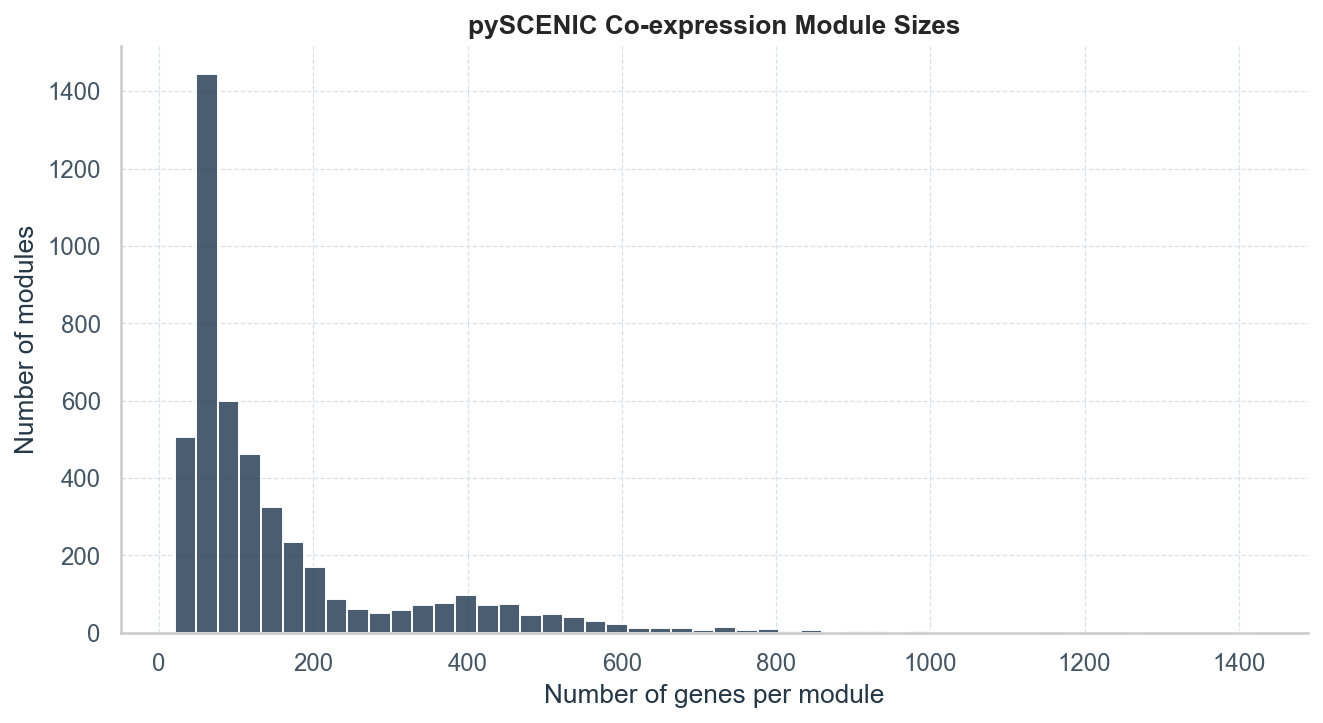

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

sns.histplot(
    data=module_summary,
    x="Number_of_genes",
    bins=50,
    color=MAIN_COLOR,
    ax=ax
)

ax.set_xlabel("Number of genes per module")
ax.set_ylabel("Number of modules")
ax.set_title("pySCENIC Co-expression Module Sizes")

plt.tight_layout()
plt.show()
savefig(RESOURCE_FOLDER / "pyscenic_module_size.jpg")

In [ ]:
modules_per_tf = (
    module_summary.groupby("TF")
    .agg(
        n_modules=("Module", "count"),
        max_module_size=("Number_of_genes", "max"),
        median_module_size=("Number_of_genes", "median")
    )
    .sort_values("max_module_size", ascending=False)
)

display(modules_per_tf.head(10))

,n_modules,max_module_size,median_module_size
TF,,,
YWHAZ,6,1420,198.0
SMAP2,6,1271,256.5
PRDM1,6,1191,146.0
BDP1,6,1185,154.0
LRRFIP1,6,1119,188.5
EEF1D,6,1116,172.0
ZBTB1,6,1088,132.5
ETS1,6,1085,194.5
HMGB2,6,1080,176.0


#### Load Modules 

In [ ]:
#with open(MODULES_FNAME, 'rb') as f:
    #modules = pickle.load(f)

### Module Comparison 
graph communities vs. pySCENIC modules

In [ ]:
community_sets = {
    f"community_{i}": set(genes)
    for i, genes in enumerate(communities, start=1)
}

scenic_sets = {
    f"scenic_{i}_{getattr(module, 'transcription_factor', 'unknown')}":
        set(module.genes)
    for i, module in enumerate(modules, start=1)
}

In [ ]:
comparison_rows = []

for community_name, community_genes in community_sets.items():
    for scenic_name, scenic_genes in scenic_sets.items():

        intersection = community_genes & scenic_genes
        union = community_genes | scenic_genes

        comparison_rows.append({
            "community": community_name,
            "scenic_module": scenic_name,
            "n_community_genes": len(community_genes),
            "n_scenic_genes": len(scenic_genes),
            "n_shared": len(intersection),
            "jaccard": (
                len(intersection) / len(union)
                if union else 0
            ),
            "community_fraction": (
                len(intersection) / len(community_genes)
                if community_genes else 0
            ),
            "scenic_fraction": (
                len(intersection) / len(scenic_genes)
                if scenic_genes else 0
            ),
        })

module_comparison = pd.DataFrame(comparison_rows)

In [ ]:
module_comparison = module_comparison.sort_values(
    ["jaccard", "n_shared"],
    ascending=False
).reset_index(drop=True)

display(module_comparison.head(10))

,community,scenic_module,n_community_genes,n_scenic_genes,n_shared,jaccard,community_fraction,scenic_fraction
0,community_21,scenic_2055_SIN3A,66,51,17,0.170000,0.257576,0.333333
1,community_51,scenic_1459_ZNF263,80,83,23,0.164286,0.287500,0.277108
2,community_21,scenic_2810_SIN3A,66,66,18,0.157895,0.272727,0.272727
3,community_51,scenic_922_ELF3,80,99,24,0.154839,0.300000,0.242424
4,community_51,scenic_3780_ZNF263,80,99,24,0.154839,0.300000,0.242424
5,community_1,scenic_2278_ZNF354A,66,51,15,0.147059,0.227273,0.294118
6,community_21,scenic_2347_ZNF714,66,51,15,0.147059,0.227273,0.294118
7,community_26,scenic_2692_NFIA,58,39,12,0.141176,0.206897,0.307692
8,community_5,scenic_2642_MAGEF1,74,64,17,0.140496,0.229730,0.265625
9,community_33,scenic_1592_AHCTF1,87,51,17,0.140496,0.195402,0.333333


## Motif Pruning

In [ ]:
%%time

df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)
df.to_csv(MOTIFS_FNAME)

display(df.head())

Enrichment                                  \
                                 AUC       NES MotifSimilarityQvalue   
TF     MotifID                                                         
ATF1   jaspar__MA0604.1     0.063661  3.025578          0.000000e+00   
ATF4   metacluster_148.1    0.061225  3.093302          0.000000e+00   
ATF7   metacluster_111.3    0.068941  3.084357          6.250900e-10   
BCL11B metacluster_162.2    0.075226  3.065939          7.549390e-11   
       metacluster_155.23   0.081905  3.546379          0.000000e+00   

                                               \
                          OrthologousIdentity   
TF     MotifID                                  
ATF1   jaspar__MA0604.1              0.918216   
ATF4   metacluster_148.1             1.000000   
ATF7   metacluster_111.3             1.000000   
BCL11B metacluster_162.2             1.000000   
       metacluster_155.23            1.000000   

                                                                              \
                                                                  Annotation   
TF     MotifID                                                                 
ATF1   jaspar__MA0604.1    motif is annotated for orthologous gene ENSMUS...   
ATF4   metacluster_148.1                          gene is directly annotated   
ATF7   metacluster_111.3   motif similar to transfac_pro__M00981 ('V$CREB...   
BCL11B metacluster_162.2   motif similar to cisbp__M00988 ('BCL11B[gene I...   
       metacluster_155.23                         gene is directly annotated   

                                                                              \
                                                                     Context   
TF     MotifID                                                                 
ATF1   jaspar__MA0604.1    (hg38_10kbp_up_10kbp_down_full_tx_v10_clust.ge...   
ATF4   metacluster_148.1   (hg38_10kbp_up_10kbp_down_full_tx_v10_clust.ge...   
ATF7   metacluster_111.3   (hg38_10kbp_up_10kbp_down_full_tx_v10_clust.ge...   
BCL11B metacluster_162.2   (hg38_10kbp_up_10kbp_down_full_tx_v10_clust.ge...   
       metacluster_155.23  (hg38_10kbp_up_10kbp_down_full_tx_v10_clust.ge...   

                                                                              \
                                                                 TargetGenes   
TF     MotifID                                                                 
ATF1   jaspar__MA0604.1    [(DNAJC19, 0.4252748954666906), (MED27, 0.5392...   
ATF4   metacluster_148.1   [(JMJD1C, 0.5217464726327123), (TAX1BP1, 0.678...   
ATF7   metacluster_111.3   [(CREB1, 0.6998776186571364), (SNX9, 0.4891629...   
BCL11B metacluster_162.2   [(RB1CC1, 1.1021206172500264), (GOLIM4, 1.7443...   
       metacluster_155.23  [(RB1CC1, 1.1021206172500264), (GOLIM4, 1.7443...   

                                     
                          RankAtMax  
TF     MotifID                       
ATF1   jaspar__MA0604.1         771  
ATF4   metacluster_148.1       1147  
ATF7   metacluster_111.3       1479  
BCL11B metacluster_162.2       1404  
       metacluster_155.23      1078

CPU times: total: 41 s
Wall time: 5min 55s



|Column |Meaning|
| --- | --- |
|AUC|Area under the Motif-Recovery Curve|
|NES|Normalized Enrichment Score|
|MotifSimilarityQvalue| Significance of Motif Similarity to an Annotated Motif|
|OrthologousIdentity| Identity Measure associated with Orthologous Motif Annotation|
|Annotation|Annotation Linking the Motif to a TF or Related Motif|
|Context|Regulatory Context Used in Enrichment|
|TargetGenes|Targets Retained for That Enriched Motif/Module|
|RankAtMax|Ranking Position at the mMximum of the Recovery Curve|


In [ ]:
regulons = df2regulons(df)

with open(REGULONS_FNAME, 'wb') as f:
    pickle.dump(regulons, f)

Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [ ]:
summary = []

for reg in regulons:
    targets = reg.gene2weight

    summary.append({
        "TF": reg.transcription_factor,
        "Regulon": reg.name,
        "N_targets": len(targets),
        "Regulon_score": reg.score,
        "NES": reg.nes,
        "Annotation": reg.annotation,
        "Context": "; ".join(sorted(map(str, reg.context))),
        "Mean_target_weight": (
            sum(targets.values()) / len(targets)
            if targets else None
        )
    })

summary = pd.DataFrame(summary)

summary = summary.sort_values(
    ["N_targets", "Regulon_score"],
    ascending=[False, False]
)

summary.to_csv(
    os.path.join(RESOURCE_FOLDER / "grn_regulons.csv"), 
    index=False
)

display(summary.head(10))
print("Total regulons:", len(summary))

,TF,Regulon,N_targets,Regulon_score,NES,Annotation,Context,Mean_target_weight
29,ELK4,ELK4(+),243,4.235700,0.0,,activating; jaspar__MA1483.2.png,0.672376
27,ELK1,ELK1(+),237,4.990298,0.0,,activating; jaspar__MA1935.1.png,0.553001
42,FOXO1,FOXO1(+),231,3.392219,0.0,,activating; taipale_tf_pairs__FLI1_FOXI1_TGTTK...,0.424069
23,ELF1,ELF1(+),212,3.217472,0.0,,activating; metacluster_122.10.png,0.307511
154,ZNF580,ZNF580(+),190,4.867689,0.0,,activating; metacluster_191.2.png,0.610989
120,STAT1,STAT1(+),179,3.271367,0.0,,activating; tfdimers__MD00064.png,0.517808
46,GABPA,GABPA(+),176,4.431689,0.0,,activating; taipale_tf_pairs__ETV2_GSC2_RSCGGA...,0.953511
48,GATA3,GATA3(+),171,3.308035,0.0,,activating; tfdimers__MD00085.png,0.485003
37,ETV3,ETV3(+),170,4.156398,0.0,,activating; metacluster_191.3.png,0.287027
38,ETV7,ETV7(+),167,7.536644,0.0,,activating; metacluster_191.3.png,0.546169


Total regulons: 162


### Export Regulons to Cytoscape Edge Table

In [ ]:
edges = []

for reg in regulons:
    tf = reg.transcription_factor

    for target, weight in reg.gene2weight.items():
        edges.append({
            "source": tf,
            
            "target": target,
            "weight": weight,
            "regulon": reg.name,
            "regulon_score": reg.score,
            "context": "; ".join(sorted(map(str, reg.context)))
        })

edges = pd.DataFrame(edges)

edges = (
    edges.sort_values("weight", ascending=False)
         .drop_duplicates(["source", "target"])
)

edges.to_csv(
    RESOURCE_FOLDER / "cytoscape_edges_regulon.csv",
    index=False
)

print("TF-target edges:", len(edges))
print("Unique TFs:", edges["source"].nunique())
print("Unique target genes:", edges["target"].nunique())

TF-target edges: 7460
Unique TFs: 162
Unique target genes: 3928


#### Load Regulons

In [ ]:
#with open(REGULONS_FNAME, 'rb') as f:
    #regulons = pickle.load(f)

# PHASE 3 - Cellular Regulon Enrichment Matrix (AUCell)
---

In [ ]:
%%time

auc_mtx = aucell(expression_data_filtered, regulons, num_workers=4)

print("AUCell matrix shape:", auc_mtx.shape)
display(auc_mtx.head())

AUCell matrix shape: (412, 162)


Regulon,ARNTL2(+),ATF1(+),ATF3(+),ATF4(+),ATF5(+),ATF6(+),ATF6B(+),ATF7(+),BACH1(+),BCL11B(+),...,ZNF528(+),ZNF529(+),ZNF580(+),ZNF620(+),ZNF639(+),ZNF721(+),ZNF740(+),ZNF75D(+),ZNF780A(+),ZNF787(+)
Cell,,,,,,,,,,,,,,,,,,,,,
AGCTCAAGTGCTGCAC-T2,0.014967,0.032291,0.0,0.027150,0.0,0.075820,0.0,0.023929,0.082801,0.016634,...,0.050679,0.000000,0.013035,0.000000,0.001854,0.013568,0.0,0.0,0.0,0.0
CTAGGTAAGTAATTGG-T2,0.003333,0.000000,0.0,0.004087,0.0,0.091859,0.0,0.000775,0.077936,0.015969,...,0.000000,0.016867,0.007369,0.000000,0.001349,0.000415,0.0,0.0,0.0,0.0
CGTGATAAGTGCAGGT-T2,0.000233,0.007713,0.0,0.011011,0.0,0.000000,0.0,0.001192,0.078763,0.027120,...,0.000000,0.008264,0.007508,0.057887,0.000000,0.027034,0.0,0.0,0.0,0.0
ATCGTCCAGCTAGATA-T2,0.000000,0.000000,0.0,0.010052,0.0,0.000000,0.0,0.011571,0.064840,0.018720,...,0.000000,0.012158,0.003050,0.000000,0.000000,0.015296,0.0,0.0,0.0,0.0
CCCTTAGCAGCCTACG-T2,0.003181,0.001858,0.0,0.010957,0.0,0.000000,0.0,0.002705,0.101983,0.023274,...,0.000000,0.000000,0.009637,0.000000,0.001312,0.030873,0.0,0.0,0.0,0.0


CPU times: total: 547 ms
Wall time: 14.3 s


In [ ]:
auc_mtx.to_csv(AUCELL_FNAME)

In [ ]:
auc_summary = pd.DataFrame({
    "mean_AUC": auc_mtx.mean(axis=0),
    "median_AUC": auc_mtx.median(axis=0),
    "sd_AUC": auc_mtx.std(axis=0),
    "variance_AUC": auc_mtx.var(axis=0)
})

auc_summary.index = (
    auc_summary.index
    .astype(str)
    .str.replace(r"\(\+\)$", "", regex=True)
)

auc_summary = auc_summary.sort_values(
    "variance_AUC", ascending=False
)

auc_summary.to_csv(
    RESOURCE_FOLDER / "grn_auc.csv"
)

display(auc_summary.head(10))

,mean_AUC,median_AUC,sd_AUC,variance_AUC
Regulon,,,,
NFE2L2,0.089049,0.055499,0.096051,0.009226
JUNB,0.087860,0.063271,0.083877,0.007035
FOSB,0.111066,0.092628,0.069753,0.004866
E2F3,0.026331,0.000000,0.060662,0.003680
ATF6,0.039094,0.000000,0.050922,0.002593
BACH1,0.083904,0.076614,0.049174,0.002418
JUND,0.151039,0.143999,0.045254,0.002048
REL,0.072611,0.067959,0.043550,0.001897
GABPB1,0.018273,0.000000,0.039741,0.001579


# Regulatory Subnetworks for Cytoscape
---

In [ ]:
TF_MODULES = {
    "hypoxia_stress": [
        "HIF1A", "EPAS1", "NFE2L2", "ATF4", "XBP1", "DDIT3"
    ],
    "EMT_plasticity": [
        "TWIST1", "SNAI1", "SNAI2", "ZEB1", "ZEB2",
        "FOXC2", "GRHL2", "OVOL1", "OVOL2",
        "PRRX1", "SIX1", "KLF8", "LEF1", "TCF7L2"
    ],
    "AP1_inflammation": [
        "JUN", "JUNB", "JUND", "FOS", "FOSB",
        "FOSL1", "FOSL2", "RELA", "NFKB1", "STAT3",
        "CEBPB", "IRF1", "IRF2"
    ],
    "migration_invasion": [
        "FOXC2", "TEAD1", "TEAD4", "YAP1", "WWTR1",
        "SMAD2", "SMAD3", "SMAD4", "RUNX1", "RUNX2",
        "PRRX1", "SIX1", "KLF8"
    ],
    "proliferation_outgrowth": [
        "E2F1", "E2F2", "E2F3", "MYC", "MYCN",
        "FOXM1", "TP53", "RB1", "SP1", "KLF5"
    ],
    "stemness_plasticity": [
        "SOX4", "SOX9", "ID1", "ID2", "ID3",
        "KLF4", "STAT3", "MYC", "SOX2", "NOTCH1", "RBPJ"
    ],
    "dormancy_relapse": [
        "NR2F1", "BHLHE41", "TP53", "FOXO3", "ATF4",
        "SMAD2", "SMAD3", "SOX9", "KLF4", "HBP1", "CDKN1A"
    ],
    "breast_lineage": [
        "ESR1", "PGR", "GATA3", "FOXA1", "FOXC1", "KLF5",
        "AR", "SOX10", "TRPS1"
    ],
    "oxidative_stress": [
        "NFE2L2", "JUNB", "FOSB", "ATF4", "XBP1", "DDIT3", "FOXO3"
    ],
    "metastatic_colonization": [
        "SP1", "KLF5", "CEBPB", "RUNX2", "RUNX1",
        "STAT3", "RELA", "MYC", "E2F1", "FOXM1"
    ],
    "immune_evasion": [
        "RELA", "NFKB1", "STAT3", "STAT1",
        "IRF1", "IRF2", "CEBPB", "JUNB", "HIF1A"
    ],
    "bone_tropism": [
        "RUNX2", "RUNX1", "TWIST1", "SNAI2", "ZEB1",
        "FOXC2", "SMAD2", "SMAD3", "STAT3"
    ]
}

In [ ]:
subnetwork_tables = {}

for module_name, selected_tfs in TF_MODULES.items():

    # Select edges originating from TFs in this module
    focused_edges = edges[
        edges["source"].isin(selected_tfs)
    ].copy()

    # Save the table in memory
    subnetwork_tables[module_name] = focused_edges

    # Export to CSV
    output_file = (
        SUBNETWORK_FOLDER / f"grn_subnetwork_{module_name}.csv"
    )

    focused_edges.to_csv(output_file, index=False)

    # Report summary
    n_tfs_found = focused_edges["source"].nunique()
    n_targets = focused_edges["target"].nunique()

    print(
        f"{module_name}: "
        f"{len(focused_edges)} edges, "
        f"{n_tfs_found}/{len(set(selected_tfs))} TFs represented, "
        f"{n_targets} unique targets"
    )

print(f"\nSaved subnetworks to: {SUBNETWORK_FOLDER}")

hypoxia_stress: 96 edges, 4/6 TFs represented, 94 unique targets
EMT_plasticity: 22 edges, 1/14 TFs represented, 22 unique targets
AP1_inflammation: 394 edges, 7/13 TFs represented, 337 unique targets
migration_invasion: 4 edges, 1/13 TFs represented, 4 unique targets
proliferation_outgrowth: 78 edges, 2/10 TFs represented, 78 unique targets
stemness_plasticity: 32 edges, 2/11 TFs represented, 32 unique targets
dormancy_relapse: 72 edges, 3/11 TFs represented, 72 unique targets
breast_lineage: 171 edges, 1/9 TFs represented, 171 unique targets
oxidative_stress: 134 edges, 6/7 TFs represented, 131 unique targets
metastatic_colonization: 103 edges, 2/10 TFs represented, 101 unique targets
immune_evasion: 235 edges, 4/9 TFs represented, 235 unique targets
bone_tropism: 0 edges, 0/9 TFs represented, 0 unique targets

Saved subnetworks to: ..\results\grn-inference\Activated T cells\T\subnetwork
